# 07 · Interpretability

Three questions, each with a different standard of evidence:

1. **Which features drive risk?** SHAP on the tabular reference model. This is
   the one that has to survive clinical review, so it is compared against known
   ICU physiology rather than admired on its own.
2. **Which neighbours does the model attend to?** GAT attention over the
   patient-similarity graph — does it weight clinically similar patients, or
   is the graph structure incidental?
3. **Does exit depth mean anything?** The claim implicit in the whole design is
   that depth tracks difficulty. If deep-exiting patients are not
   distinguishable from shallow-exiting ones, the halting policy is arbitrary
   even when the aggregate numbers look fine.

A caution carried from notebook 02: measurement intensity is itself predictive,
so an importance ranking dominated by `*_count` and `*_missing` columns is
telling you about process of care, not physiology. That is a real signal and not
leakage, but it is a different claim from "the model learned medicine".

In [1]:
exec(open("/kaggle/working/clinical-eegnn/notebooks/src/_bootstrap.py").read())
from src import mimic_iv, graph_build as gb
from src.data_prep import make_splits, impute_and_scale, feature_names_after_scaling
from src.train import set_seed, get_device
from src.model import EEGNN
import torch, matplotlib.pyplot as plt

cfg = mimic_cfg()
set_seed(cfg["seed"])
X_raw, y, names, meta = mimic_iv.build_cohort(cfg, verbose=False)
train, val, test = make_splits(y, cfg["seed"])
X = impute_and_scale(X_raw, train)
full_names = feature_names_after_scaling(names, X_raw, train)
data = gb.build_graph(X, y, (train, val, test), cfg, meta=meta,
                      cache_dir=CACHE).to(get_device())
print(f"{X.shape[1]} features ({len(names)} raw + "
      f"{X.shape[1]-len(names)} missingness indicators)")

542 features (331 raw + 211 missingness indicators)


## 1 · SHAP on the tabular reference

Runs in the torch-free worker subprocess (`src/_omp_guard`), the same isolation
the XGBoost baseline uses.

In [2]:
from src.explain import shap_feature_importance

t0 = time.time()
shap_res = shap_feature_importance(X, y, (train, val, test), full_names,
                                   seed=cfg["seed"], max_display=25)
print(f"[{time.time()-t0:.1f}s]")

# `ranking` is a list of (feature, mean|SHAP|) already sorted descending.
imp = pd.DataFrame(shap_res["ranking"], columns=["feature", "mean_abs_shap"])
print(imp.to_string(index=False))

[9.7s]
                feature  mean_abs_shap
                    age       0.347019
     tx_urine_ml_per_hr       0.331650
     vit_gcs_motor_last       0.307901
    vit_gcs_verbal_last       0.282359
     vit_resp_rate_mean       0.232965
             unit_cvicu       0.160839
           lab_bun_last       0.144385
       vit_gcs_eye_mean       0.116406
       vit_gcs_eye_last       0.111556
      vit_gcs_eye_count       0.096958
  lab_bicarbonate_first       0.091479
unit_neuro_intermediate       0.087481
           lab_ptt_last       0.087215
            lab_bun_max       0.082792
      lab_platelets_max       0.080850
           vit_sbp_last       0.080790
vit_glucose_chart_count       0.077403
       vit_temp_f_first       0.073853
      vit_resp_rate_min       0.072050
    vit_heart_rate_last       0.071240
            vit_sbp_min       0.071162
    vit_heart_rate_mean       0.069956
      lab_alk_phos_mean       0.067239
          lab_po2_first       0.066266
     vit_gcs_motor

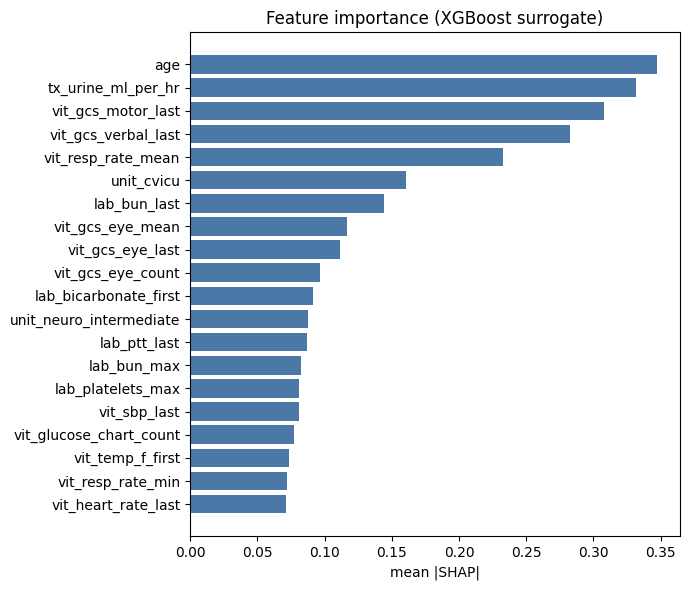

In [3]:
top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top["feature"], top["mean_abs_shap"], color="#4C78A8")
ax.set_xlabel("mean |SHAP|"); ax.set_title("Feature importance (XGBoost surrogate)")
plt.tight_layout(); plt.show()

### Reading the ranking by block

Grouping importance by feature block says which *kind* of information the model
leans on, which is more robust than any individual feature's rank.

In [4]:
def block_of(feature):
    base = feature.replace("_missing", "")
    for name, cols in meta["views"].items():
        if base in [names[c] for c in cols if c < len(names)]:
            return name + ("_missing" if feature.endswith("_missing") else "")
    return "other"

imp2 = imp.copy()
imp2["block"] = imp2["feature"].map(block_of)
by_block = imp2.groupby("block")["mean_abs_shap"].agg(
    ["sum", "mean", "count"]).sort_values("sum", ascending=False)
print(by_block.round(5).to_string())
print("\nNote: this ranks only the top-%d features, so block sums are a view of "
      "what dominates the head of the ranking, not total block importance."
      % len(imp))

                  sum     mean  count
block                                
vitals        1.72892  0.12349     14
labs          0.62023  0.08860      7
demographics  0.59534  0.19845      3
treatment     0.33165  0.33165      1

Note: this ranks only the top-25 features, so block sums are a view of what dominates the head of the ranking, not total block importance.


## 2 · Attention over the patient graph

val AUROC 0.858
edges with attention: 444,159
mean attention, same-outcome neighbours : 0.039461
mean attention, different-outcome        : 0.041782
ratio                                    : 0.944


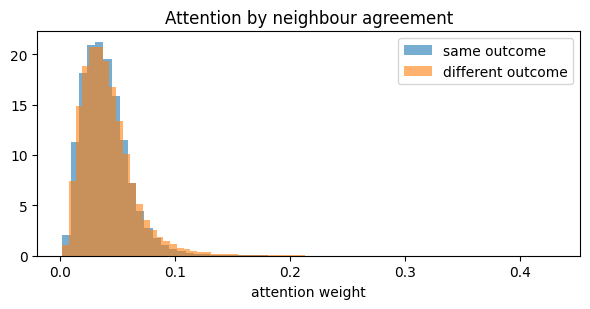

In [5]:
from src.baselines import GAT, train_plain_gnn
from src.explain import attention_weights

set_seed(cfg["seed"])
gat, gat_val = train_plain_gnn(
    GAT(data.x.shape[1], cfg["model"]["hidden_dim"], n_layers=2,
        dropout=cfg["model"]["dropout"]).to(get_device()), data, cfg)
att = attention_weights(gat, data)
print("val AUROC", round(gat_val, 4))

if att is None:
    print("this model exposes no attention weights — skipping")
else:
    a = att["alpha"].ravel()
    ei_att = att["edge_index"]
    yt = data.y.cpu().numpy()
    src, dst = ei_att[0], ei_att[1]
    same = yt[src] == yt[dst]

    print(f"edges with attention: {len(a):,}")
    print(f"mean attention, same-outcome neighbours : {a[same].mean():.6f}")
    print(f"mean attention, different-outcome        : {a[~same].mean():.6f}")
    print(f"ratio                                    : "
          f"{a[same].mean() / max(a[~same].mean(), 1e-12):.3f}")

    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.hist(a[same], bins=60, alpha=.6, density=True, label="same outcome")
    ax.hist(a[~same], bins=60, alpha=.6, density=True, label="different outcome")
    ax.set_xlabel("attention weight"); ax.legend()
    ax.set_title("Attention by neighbour agreement")
    plt.tight_layout(); plt.show()

A ratio near 1.0 means attention is not distinguishing useful neighbours from
useless ones — the model is using the graph as a smoother rather than as a
retrieval mechanism. That is not fatal, but it undercuts any claim that the
model "finds similar patients".

## 3 · Does exit depth track difficulty?

In [6]:
from src.explain import exit_depth_vs_difficulty

ckpt = torch.load(f"{CACHE}/eegnn_model.pt", map_location=get_device(),
                  weights_only=False)
model = EEGNN(data.x.shape[1], ckpt["cfg"]).to(get_device())
model.load_state_dict(ckpt["state_dict"])
model.use_exits = True

diff = exit_depth_vs_difficulty(model, data, cfg, split="test")
for k, v in diff.items():
    if not hasattr(v, "shape"):
        print(f"  {k:34s} {round(v, 4) if isinstance(v, float) else v}")

  corr_depth_vs_margin               0.0478
  mean_depth_correct                 6.3606
  mean_depth_incorrect               6.1752
  depth_by_quartile_of_margin        [6.035067873303167, 6.562853907134768, 6.074745186862967, 6.524348810872027]
  risk_proxy                         severity
  corr_depth_vs_true_ambiguity       0.2127
  corr_depth_vs_risk                 0.1018
  depth_by_quartile_of_risk          [5.1945701357466065, 6.469988674971687, 7.157417893544734, 6.37599093997735]


`corr_depth_vs_margin` should be **negative**: patients the model is unsure
about (small margin) ought to use more layers. `mean_depth_incorrect` above
`mean_depth_correct` says the same thing — the model spent longer on the cases
it ultimately got wrong, which is the behaviour you want from an adaptive-depth
system even when it fails.

`corr_depth_vs_risk` uses `criticalness`, an external severity proxy that is
never a model input, so it is the least circular of the three.

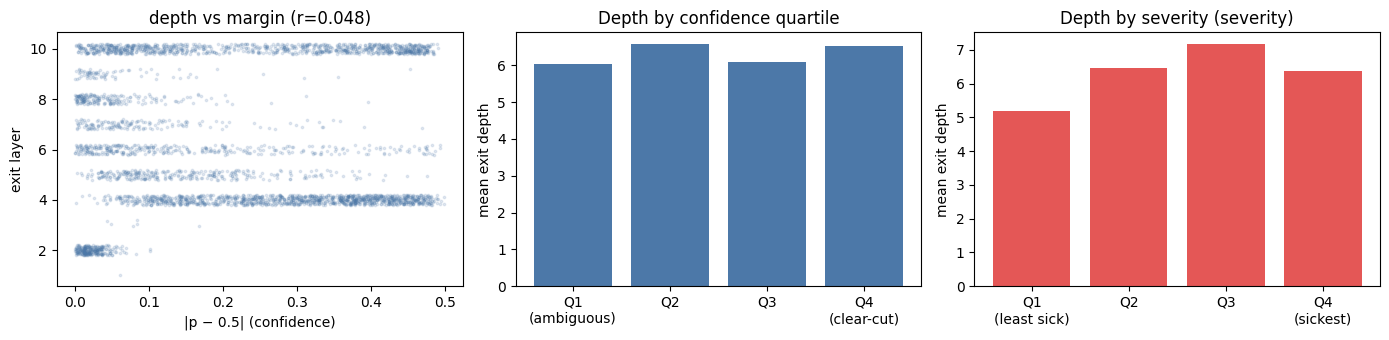

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].scatter(diff["margin"], diff["depth"] + np.random.uniform(-.2, .2, len(diff["depth"])),
              s=3, alpha=.15, color="#4C78A8")
ax[0].set_xlabel("|p − 0.5| (confidence)"); ax[0].set_ylabel("exit layer")
ax[0].set_title(f"depth vs margin (r={diff['corr_depth_vs_margin']:.3f})")

q = diff["depth_by_quartile_of_margin"]
ax[1].bar(["Q1\n(ambiguous)", "Q2", "Q3", "Q4\n(clear-cut)"], q, color="#4C78A8")
ax[1].set_ylabel("mean exit depth"); ax[1].set_title("Depth by confidence quartile")

if "depth_by_quartile_of_risk" in diff:
    ax[2].bar(["Q1\n(least sick)", "Q2", "Q3", "Q4\n(sickest)"],
              diff["depth_by_quartile_of_risk"], color="#E45756")
    ax[2].set_ylabel("mean exit depth")
    ax[2].set_title(f"Depth by severity ({diff.get('risk_proxy','')})")
plt.tight_layout(); plt.show()

The right-hand panel is the clinical claim in one picture: **depth should rise
with severity.** A flat or falling profile means the compute saving is coming
partly out of the sickest patients, which is the inverted-ordering failure of
HANDOVER §6.3 and would need fixing before any deployment argument.

In [8]:
json.dump({
    "top_features": imp.head(25).to_dict("records"),
    "importance_by_block": by_block.reset_index().to_dict("records"),
    "attention_same_vs_diff": (
        {"same": float(a[same].mean()), "diff": float(a[~same].mean())}
        if att is not None else None),
    "depth_vs_difficulty": {k: v for k, v in diff.items() if not hasattr(v, "shape")},
}, open(f"{CACHE}/interpretability.json", "w"), indent=2, default=float)
print("wrote interpretability.json")

wrote interpretability.json


## Caveats for the write-up

- SHAP here explains the **XGBoost reference**, not the GNN. It describes the
  signal available in the features, not the mechanism the graph model uses.
  Presenting it as an explanation of EEGNN would overclaim.
- Attention comes from a separately trained GAT, not from the SAS-GNN backbone,
  which is weight-tied and has no attention to inspect.
- Every number here is single-seed. HANDOVER §7 requires mean±std over seeds
  before anything is quoted as a result.